In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 01. Data Wrangling

In [2]:
#Importar el dataset
df_healthcare = pd.read_csv('/content/healthcare_dataset.csv')
df_healthcare

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
0,Bobby JacksOn,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328,Urgent,2024-02-02,Paracetamol,Normal
1,LesLie TErRy,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265,Emergency,2019-08-26,Ibuprofen,Inconclusive
2,DaNnY sMitH,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205,Emergency,2022-10-07,Aspirin,Normal
3,andrEw waTtS,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450,Elective,2020-12-18,Ibuprofen,Abnormal
4,adrIENNE bEll,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.317814,458,Urgent,2022-10-09,Penicillin,Abnormal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
55495,eLIZABeTH jaCkSOn,42,Female,O+,Asthma,2020-08-16,Joshua Jarvis,Jones-Thompson,Blue Cross,2650.714952,417,Elective,2020-09-15,Penicillin,Abnormal
55496,KYle pEREz,61,Female,AB-,Obesity,2020-01-23,Taylor Sullivan,Tucker-Moyer,Cigna,31457.797307,316,Elective,2020-02-01,Aspirin,Normal
55497,HEATher WaNG,38,Female,B+,Hypertension,2020-07-13,Joe Jacobs DVM,"and Mahoney Johnson Vasquez,",UnitedHealthcare,27620.764717,347,Urgent,2020-08-10,Ibuprofen,Abnormal
55498,JENniFER JOneS,43,Male,O-,Arthritis,2019-05-25,Kimberly Curry,"Jackson Todd and Castro,",Medicare,32451.092358,321,Elective,2019-05-31,Ibuprofen,Abnormal


In [3]:
#Ver la información básica
df_healthcare.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55500 entries, 0 to 55499
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Name                55500 non-null  object 
 1   Age                 55500 non-null  int64  
 2   Gender              55500 non-null  object 
 3   Blood Type          55500 non-null  object 
 4   Medical Condition   55500 non-null  object 
 5   Date of Admission   55500 non-null  object 
 6   Doctor              55500 non-null  object 
 7   Hospital            55500 non-null  object 
 8   Insurance Provider  55500 non-null  object 
 9   Billing Amount      55500 non-null  float64
 10  Room Number         55500 non-null  int64  
 11  Admission Type      55500 non-null  object 
 12  Discharge Date      55500 non-null  object 
 13  Medication          55500 non-null  object 
 14  Test Results        55500 non-null  object 
dtypes: float64(1), int64(2), object(12)
memory usage: 6.4

In [4]:
#Analizar valores duplicados
df_healthcare[df_healthcare.duplicated(keep=False)].sort_values(by='Name')

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
54285,ABIgaIL YOung,41,Female,O+,Hypertension,2022-12-15,Edward Kramer,Moore-Mcdaniel,UnitedHealthcare,1983.568297,192,Elective,2023-01-13,Ibuprofen,Normal
42407,ABIgaIL YOung,41,Female,O+,Hypertension,2022-12-15,Edward Kramer,Moore-Mcdaniel,UnitedHealthcare,1983.568297,192,Elective,2023-01-13,Ibuprofen,Normal
26025,ALIcia taYLoR,78,Male,O+,Asthma,2022-09-18,Dawn Burton,Wright LLC,Aetna,31465.274979,149,Elective,2022-10-15,Aspirin,Inconclusive
53104,ALIcia taYLoR,78,Male,O+,Asthma,2022-09-18,Dawn Burton,Wright LLC,Aetna,31465.274979,149,Elective,2022-10-15,Aspirin,Inconclusive
50151,AMy GREEN,79,Female,B+,Obesity,2021-03-30,Brett Johnson,Taylor-Williamson,UnitedHealthcare,23402.358491,249,Elective,2021-04-27,Penicillin,Abnormal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
50070,wiLliam LEe,27,Female,O+,Arthritis,2020-01-31,Lauren Montgomery,Winters-Simon,Cigna,46229.434901,153,Elective,2020-02-13,Lipitor,Normal
53693,willIAM DUnCan,78,Female,B-,Arthritis,2019-08-04,Margaret Rice,"and Hobbs Rice, Miller",UnitedHealthcare,4537.845577,383,Elective,2019-08-17,Aspirin,Abnormal
27374,willIAM DUnCan,78,Female,B-,Arthritis,2019-08-04,Margaret Rice,"and Hobbs Rice, Miller",UnitedHealthcare,4537.845577,383,Elective,2019-08-17,Aspirin,Abnormal
51964,zaCHAry balL,85,Female,B-,Diabetes,2020-04-25,Matthew Conley,"and Morgan Jones, Matthews",Blue Cross,15207.547262,202,Emergency,2020-05-25,Penicillin,Inconclusive


In [5]:
#Eliminar duplicados
df_healthcare = df_healthcare.drop_duplicates(keep='first')

In [6]:
#Convertir campos de fechas a formato datetime
df_healthcare['Discharge Date'] = pd.to_datetime(df_healthcare['Discharge Date'], errors='coerce')
df_healthcare['Date of Admission'] = pd.to_datetime(df_healthcare['Date of Admission'], errors='coerce')

/tmp/ipykernel_4493/3953697942.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_healthcare['Discharge Date'] = pd.to_datetime(df_healthcare['Discharge Date'], errors='coerce')
/tmp/ipykernel_4493/3953697942.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_healthcare['Date of Admission'] = pd.to_datetime(df_healthcare['Date of Admission'], errors='coerce')


In [7]:
#Eliminar espacios en blanco
for col in df_healthcare.select_dtypes(include='object').columns:
  df_healthcare[col] = df_healthcare[col].str.strip()

/tmp/ipykernel_4493/430832010.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_healthcare[col] = df_healthcare[col].str.strip()


In [8]:
#Eliminar columnas innecesarias
df_healthcare = df_healthcare.drop(columns='Name')

In [9]:
#Crear una columna con el tiempo de internamiento en el hospital
df_healthcare['Days of Stay'] = (df_healthcare['Discharge Date'] - df_healthcare['Date of Admission']).dt.days

In [10]:
#Revisar resultado de los cambios
df_healthcare.head(5)

,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results,Days of Stay
0,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328,Urgent,2024-02-02,Paracetamol,Normal,2
1,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265,Emergency,2019-08-26,Ibuprofen,Inconclusive,6
2,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205,Emergency,2022-10-07,Aspirin,Normal,15
3,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450,Elective,2020-12-18,Ibuprofen,Abnormal,30
4,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.317814,458,Urgent,2022-10-09,Penicillin,Abnormal,20


# 02. Exploraty Data Analysis

**1. ¿Qué condiciones médicas generan mayores costes hospitalarios?**

In [76]:
costes = (df_healthcare.groupby('Medical Condition')['Billing Amount'].sum().sort_values(ascending=True)/1000000).round(2)
costes

,Billing Amount
Medical Condition,
Cancer,229.89
Asthma,233.14
Hypertension,233.38
Arthritis,235.17
Obesity,236.01
Diabetes,236.49


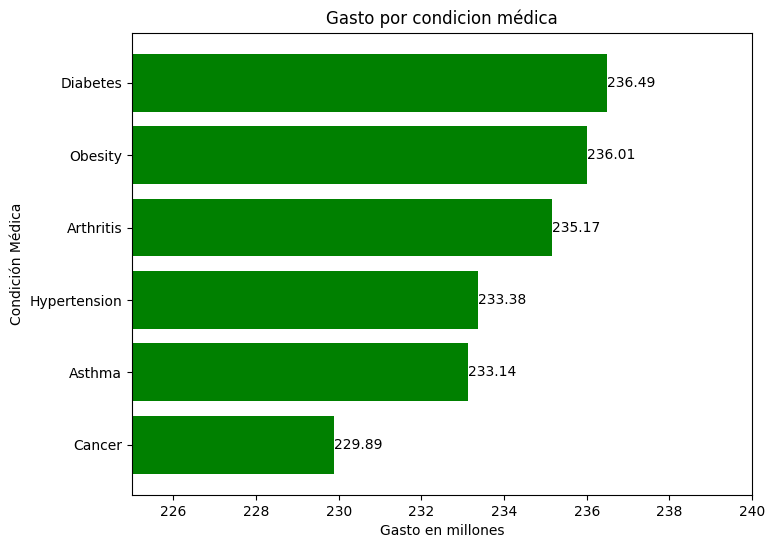

In [100]:
plt.figure(figsize=(8,6))

bars = plt.barh(costes.index, costes.values, color='green')
plt.bar_label(bars)
plt.xlim(225,240)
plt.xlabel('Gasto en millones')
plt.ylabel('Condición Médica')
plt.title('Gasto por condicion médica')

plt.show()

**Conclusión:**

Al analizar los resultados, se observa que los gastos totales por enfermedad son bastante similares. La diabetes registra el mayor gasto, con 236.49 millones de dólares, seguida de la obesidad 236.01 millones y la artritis 235.17 millones. Por otro lado, el cáncer presenta el menor gasto, con 229.89 millones, una diferencia aproximada de 7 millones del valor más alto.

Esto demuestra que ninguna enfermedad concentra una proporción significativamente mayor del gasto hospitalario, sino que los costes están distribuidos de manera bastante equilibrada entre las distintas patologías.

**2. ¿Cómo han evolucionado los ingresos hospitalarios del Cancer, Hypertension y Diabetes a lo largo del tiempo?**

In [107]:
timeline = pd.crosstab(df_healthcare['Date of Admission'].dt.year,
                      df_healthcare['Medical Condition'])
timeline.index.name='Año Ingreso'
timeline.columns.name='Concidión Médica'
timeline[['Cancer', 'Diabetes','Hypertension']]

Concidión Médica,Cancer,Diabetes,Hypertension
Año Ingreso,,,
2019,1272,1233,1175
2020,1882,1792,1883
2021,1728,1779,1849
2022,1809,1922,1818
2023,1831,1838,1829
2024,618,652,597


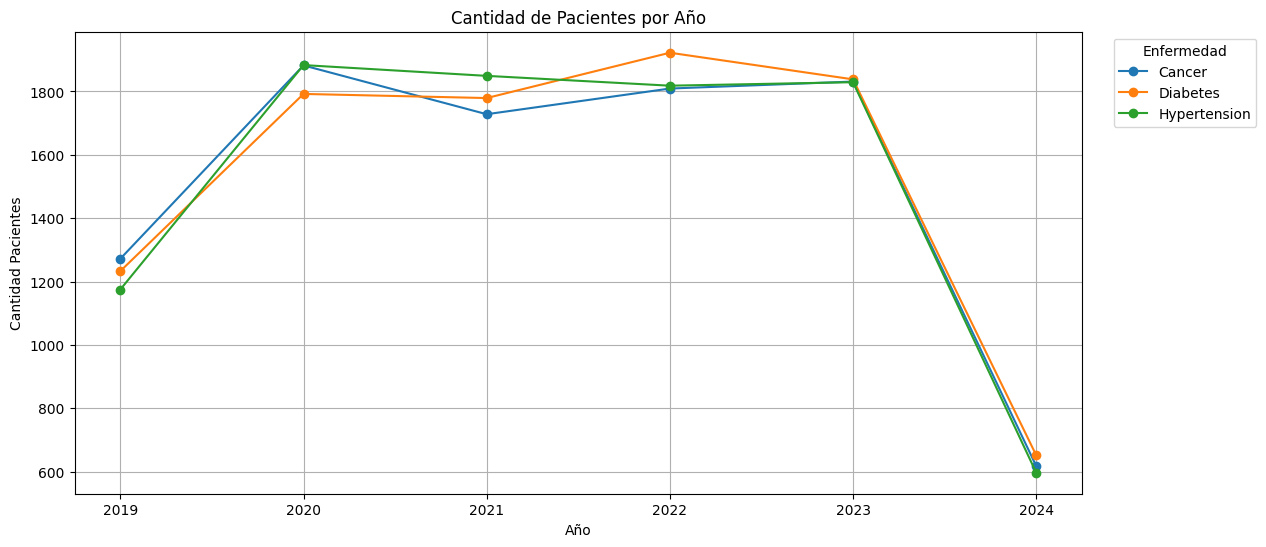

In [108]:
plt.figure(figsize=(13,6))

plt.plot(timeline[['Cancer', 'Diabetes', 'Hypertension']], marker='o', label=['Cancer', 'Diabetes', 'Hypertension'])
plt.title('Cantidad de Pacientes por Año')
plt.xlabel('Año')
plt.ylabel('Cantidad Pacientes')
plt.legend(bbox_to_anchor=(1.18, 1), title='Enfermedad')
plt.grid(True)

plt.show()

**Conclusión:**

Los datos muestran un incremento importante de los ingresos entre 2019 y 2020 en las tres enfermedades. A partir de 2020, las cifras se mantienen sin variar mucho hasta 2023, oscilando entre 1700 y 1900 ingresos anuales.

Por último, la caída registrada en 2024 probablemente se deba a que los datos de ese año están incompletos. En general, dejando de lado esta anomalía, los ingresos hospitalarios presentan un comportamiento bastante estable durante el periodo analizado.

**3. ¿Existen diferencias en la duración de la estancia hospitalaria según el tipo de admisión?**

In [113]:
estancia_admision = (df_healthcare.groupby('Admission Type')['Days of Stay'].mean().round(2).sort_values(ascending=False))
estancia_admision.index.name = 'Tipo Admisión'
estancia_admision

,Days of Stay
Tipo Admisión,
Emergency,15.58
Elective,15.51
Urgent,15.40


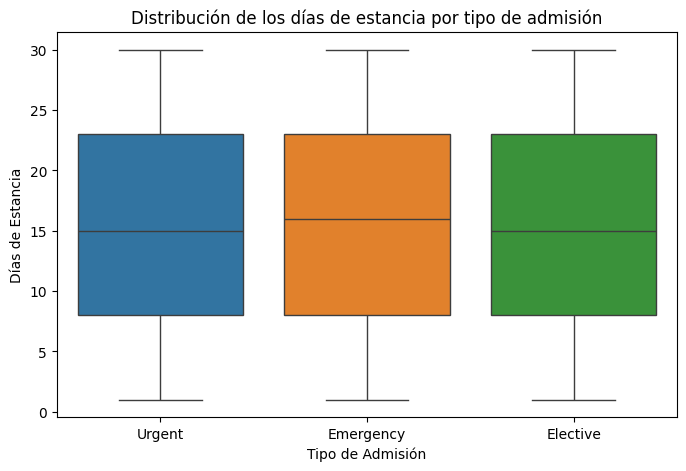

In [105]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df_healthcare,
    x='Admission Type',
    y='Days of Stay',
    hue='Admission Type'
)
plt.title('Distribución de los días de estancia por tipo de admisión')
plt.xlabel('Tipo de Admisión')
plt.ylabel('Días de Estancia')

plt.show()

**Conclusión:**

Al analizar los tiempos de estancia según el tipo de admisión, se observa que las diferencias son mínimas. Las emergencias presentan una media de 15.58 días, las admisiones electivas 15.51 días y las urgentes 15.40 días.

El gráfico de caja confirma que tanto la distribución como la dispersión de los tiempos de hospitalización son muy similares en los tres casos. Esto indica que el tipo de admisión no parece tener una influencia fuerte en la duración de la estancia hospitalaria.

**4. ¿Cómo varían las condiciones médicas según el grupo de edad de los pacientes?**

In [18]:
df_healthcare['Age Group'] = pd.cut(df_healthcare['Age'],
                                    bins=[0,18,35,50,65,80],
                                    labels=['0-18', '18-35', '35-50', '50-65', '65+'])

In [116]:
edad_condicion = pd.crosstab(df_healthcare['Age Group'],
                             df_healthcare['Medical Condition'],
                             normalize='index')
edad_condicion.index.name = 'Rango Edad'
edad_condicion.columns.name = 'Condición Médica'
edad_condicion

Condición Médica,Arthritis,Asthma,Cancer,Diabetes,Hypertension,Obesity
Rango Edad,,,,,,
0-18,0.168172,0.169300,0.164786,0.158014,0.161400,0.178330
18-35,0.167320,0.167616,0.167986,0.164139,0.165249,0.167690
35-50,0.169475,0.162982,0.163228,0.172105,0.165283,0.166927
50-65,0.164986,0.160839,0.166938,0.169702,0.166531,0.171003
65+,0.168085,0.168746,0.166433,0.168581,0.168994,0.159160


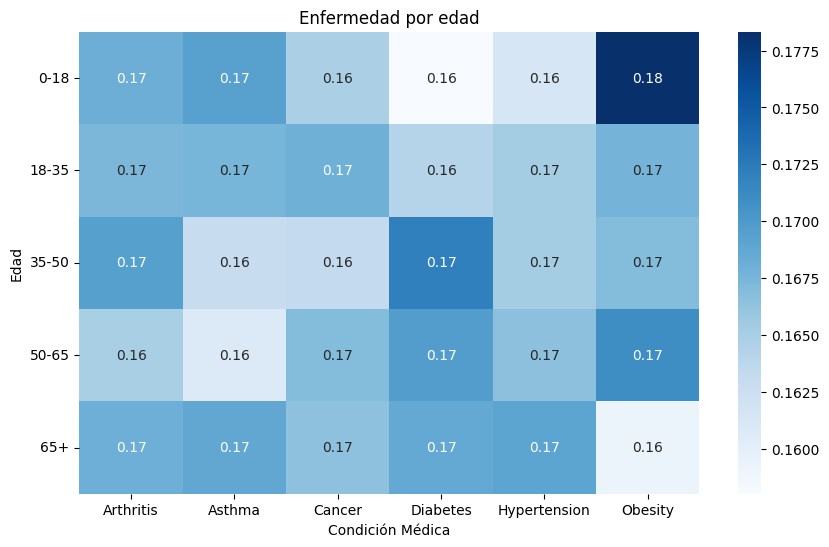

In [117]:
plt.figure(figsize=(10,6))

sns.heatmap(edad_condicion, annot=True, cmap='Blues')
plt.yticks(rotation=0)
plt.xlabel('Condición Médica')
plt.ylabel('Edad')
plt.title('Enfermedad por edad')

plt.show()

**Conclusión:**

Al analizar la distribución de las enfermedades por grupos de edad, se observa un comportamiento muy similar con porcentajes que se mantienen entre el 16% y el 17% en prácticamente todas las categorías.

El mapa de calor confirma que no hay mucha variación entre los grupos de edad y las enfermedades. Por lo tanto, se puede decir que no se aprecia una relación fuerte entre el grupo de edad y la distribución de las enfermedades analizadas.

**5. ¿El tipo de sangre influye en el tiempo de recuperación de hombres con cancer?**

In [119]:
df_hombres_cancer = df_healthcare[(df_healthcare['Gender'] == 'Male') &(df_healthcare['Medical Condition']=='Cancer')]
recuperacion_por_sangre = df_hombres_cancer.groupby('Blood Type')['Days of Stay'].mean()
recuperacion_por_sangre.index.name = 'Tipo Sangre'
recuperacion_por_sangre

,Days of Stay
Tipo Sangre,
A+,15.240942
A-,15.524138
AB+,15.709282
AB-,15.518584
B+,15.762458
B-,14.953982
O+,15.145614
O-,15.038664


In [120]:
tiempo_recuperacion = pd.DataFrame({
                      'Promedio Dias Recuperación': (recuperacion_por_sangre).round(2),
                      'Cantidad Pacientes': df_hombres_cancer['Blood Type'].value_counts().sort_index().values
})
tiempo_recuperacion.index.name = 'Tipo de Sangre'
tiempo_recuperacion

,Promedio Dias Recuperación,Cantidad Pacientes
Tipo de Sangre,,
A+,15.24,552
A-,15.52,580
AB+,15.71,571
AB-,15.52,565
B+,15.76,602
B-,14.95,565
O+,15.15,570
O-,15.04,569


**Conclusión:**

Al analizar a los hombres diagnosticados con cáncer, vemos que el tipo de sangre no parece influir en el tiempo que permanecen hospitalizados. Los promedios son bastante similares en todos los grupos, con valores que van desde los 14.95 días (B-) hasta los 15.76 días (B+).

Además, la cantidad de pacientes en cada grupo sanguíneo es bastante parecida, por lo que las pequeñas diferencias no parecen mostrar ningún patrón importante. En conclusión, los datos no muestran una relación clara entre el tipo de sangre y la duración de la hospitalización.

**6. ¿Qué factores favorecen la obtención de un resultado de prueba "Normal"?**

In [123]:
factores = ['Age Group', 'Blood Type', 'Medical Condition', 'Medication']
mejores_resultados = []
for col in factores:
  tabla = pd.crosstab(
      df_healthcare[col],
      df_healthcare['Test Results'],
      normalize='index'
  ).sort_values(by='Normal', ascending=False)
  mejores_resultados.append([col, tabla.index[0], tabla.iloc[0]['Normal']])
  print('='*50)
  print(f'Columna {col} \n{tabla}')

Columna Age Group 
Test Results  Abnormal  Inconclusive    Normal
Age Group                                     
0-18          0.326185      0.318284  0.355530
18-35         0.330720      0.327465  0.341815
65+           0.336418      0.328568  0.335014
35-50         0.335251      0.332374  0.332374
50-65         0.340868      0.334526  0.324606
Columna Blood Type 
Test Results  Abnormal  Inconclusive    Normal
Blood Type                                    
AB-           0.336049      0.323538  0.340413
B-            0.338184      0.326979  0.334837
A-            0.335170      0.330386  0.334445
O-            0.336420      0.329218  0.334362
O+            0.339314      0.327061  0.333625
AB+           0.331444      0.335513  0.333043
A+            0.335557      0.334687  0.329756
B+            0.331300      0.341176  0.327524
Columna Medical Condition 
Test Results       Abnormal  Inconclusive    Normal
Medical Condition                                  
Asthma             0.327653    

In [124]:
factores_normal = pd.DataFrame(
    mejores_resultados,
    columns=['Factor', 'Categoria', 'Porcentaje_Normal']
)
factores_normal['Porcentaje_Normal'] = (factores_normal['Porcentaje_Normal']*100).round(2)
factores_normal

,Factor,Categoria,Porcentaje_Normal
0,Age Group,0-18,35.55
1,Blood Type,AB-,34.04
2,Medical Condition,Asthma,34.26
3,Medication,Aspirin,33.65


**Conclusión:**

Al analizar qué grupos presentan una mayor proporción de resultados "Normales", destacan los pacientes de 0-18 años (35.55%), el grupo sanguíneo AB- (34.04%), los diagnosticados con asma (34.26%) y quienes tomaron aspirina (33.65%).

Sin embargo, todos estos porcentajes solo muestran unas diferencias bastante pequeñas. En general, los datos no muestran una relación clara que permita afirmar que la edad, el tipo de sangre, la enfermedad o el tratamiento influyan en la obtención de resultados normales.

**7. ¿Qué condiciones médicas muestran una mayor diferencia entre pacientes ingresados de forma Emergency y Elective en términos de tiempo de recuperación?**

In [25]:
tabla_comparativa = df_healthcare.groupby(['Medical Condition', 'Admission Type'])['Days of Stay'].mean().round(2).unstack()
tabla_comparativa['Diferencia'] = tabla_comparativa['Elective'] - tabla_comparativa['Emergency']
tabla_comparativa = tabla_comparativa.drop(columns='Urgent')
tabla_comparativa = tabla_comparativa.sort_values(by='Diferencia', ascending=False)
tabla_comparativa

Admission Type,Elective,Emergency,Diferencia
Medical Condition,,,
Asthma,15.73,15.55,0.18
Arthritis,15.62,15.50,0.12
Hypertension,15.46,15.35,0.11
Diabetes,15.62,15.59,0.03
Obesity,15.40,15.50,-0.10
Cancer,15.25,16.01,-0.76


**Conclusión:**

Al comparar los tiempos de hospitalización entre los ingresos programados (Elective) y los de emergencia (Emergency), vemos que en la mayoría de las enfermedades las diferencias son mínimas. Por ejemplo, en el asma apenas hay 0.18 días de diferencia y en la artritis 0.12 días.

Sin embargo, el cáncer destaca con una diferencia de -0.76 días. Esto significa que los pacientes que ingresan por emergencia permanecen hospitalizados en promedio 16.01 días, frente a los 15.25 días de quienes ingresan de forma programada. Esa es la diferencia más grande del análisis.

**8. ¿Qué aseguradoras presentan los mayores costes hospitalarios promedio para cada condición médica?**

In [38]:
costos_aseguradora = pd.pivot_table(df_healthcare, values='Billing Amount', index='Medical Condition', columns='Insurance Provider', aggfunc='mean').round(2)
costos_aseguradora

Insurance Provider,Aetna,Blue Cross,Cigna,Medicare,UnitedHealthcare
Medical Condition,,,,,
Arthritis,25473.95,25799.66,25306.74,25312.17,25668.94
Asthma,25849.52,25134.72,25622.78,25775.45,25793.31
Cancer,24943.74,25062.44,25549.74,25316.42,24882.18
Diabetes,25549.13,25826.32,25676.11,25711.12,25532.86
Hypertension,25873.86,25688.53,24823.16,25839.63,25281.17
Obesity,25613.90,26079.99,26158.57,25817.38,25331.09


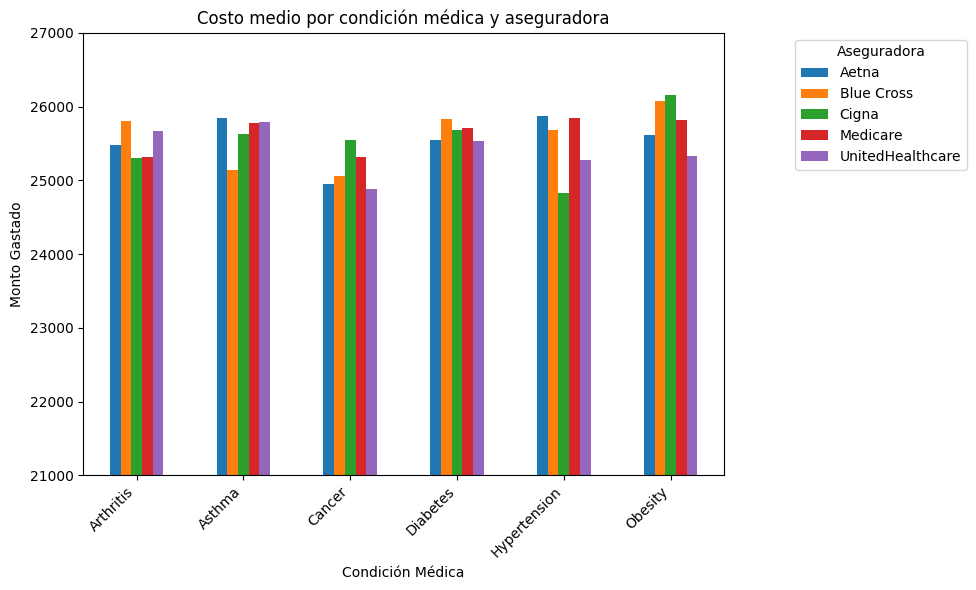

In [73]:
costos_aseguradora.plot(kind='bar', figsize=(10,6))
plt.xticks(rotation=45, ha='right')
plt.xlabel('Condición Médica')
plt.ylabel('Monto Gastado')
plt.title('Costo medio por condición médica y aseguradora')
plt.ylim(21000, 27000)
plt.legend(bbox_to_anchor=(1.1, 1), title='Aseguradora')
plt.tight_layout()

plt.show()

**Conclusión:**

Al analizar los costes hospitalarios promedio por aseguradora, vemos que no hay una única compañía que tenga los valores más altos en todas las enfermedades. Blue Cross lidera en artritis (25,799.66) y diabetes (25,826.32), mientas que Aetna lidera en asma (25,849.52) e hipertensión (25,873.86), Cigna en cáncer (25,549.74) y obesidad (26,158.57).

Sin embargo, lo más llamativo es que las diferencias entre aseguradoras son bastante pequeñas. En general, los costes promedio son muy similares, lo que sugiere que los importes facturados por el hospital mantienen cierta uniformidad, independientemente de la aseguradora del paciente.